In [2]:
# Numerical calculations
import numpy as np

# Data manipulation
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt

# File paths
from pathlib import Path

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Model evaluation
from sklearn.metrics import r2_score, mean_squared_error

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Path to the full dataset
DATA_PATH = Path("data/pallas_hackathon_data")

# Load Campaign A and Campaign B
A = pd.read_parquet(DATA_PATH / "campaign_A.parquet")
B = pd.read_parquet(DATA_PATH / "campaign_B.parquet")

# Check dataset dimensions
print("Campaign A:", A.shape)
print("Campaign B:", B.shape)

# Display the first five rows of Campaign A
#display(A.head())

Campaign A: (13073, 35)
Campaign B: (5286, 35)


## Define input and output parameters

In [4]:
# Input features: electron beam properties + known laser focus
FEATURES = [
    "E_med_MeV",
    "dE_mad",
    "q_end",
    "i_peak",
    "n_emit_x",
    "sigma_z",
    "sigma_y",
    "div_rms",
    "x_of"
]

# Target parameters: accelerator settings
TARGETS = ["p_1", "a_0", "c_N2"]

# Select injected simulations from the random scan
A_injected = A[
    (A["scan"] == "random") &
    (A["injected"] == True)
].copy()

print("Total Campaign A simulations:", len(A))
print("Selected injected simulations:", len(A_injected))

# Examine inputs and targets
#display(A_injected[FEATURES + TARGETS].head())

Total Campaign A simulations: 13073
Selected injected simulations: 7208


,E_med_MeV,dE_mad,q_end,i_peak,n_emit_x,sigma_z,sigma_y,div_rms,x_of,p_1,a_0,c_N2
0,176.890297,0.062651,1.508267e-10,7701.320948,0.000001,0.000002,0.000002,0.005604,740.016691,51.967970,1.328588,0.031888
1,117.437183,0.187095,2.720700e-10,12166.720834,0.000004,0.000003,0.000004,0.011650,914.823751,81.175615,1.278433,0.041408
3,89.495034,0.372771,2.707900e-10,9867.215564,0.000006,0.000005,0.000005,0.016154,560.282091,68.886697,1.195013,0.072505
4,115.507544,0.207592,1.948150e-10,8616.965730,0.000016,0.000006,0.000008,0.017338,790.421058,97.236441,1.116539,0.103158
5,116.282736,0.159890,2.759856e-10,10639.863480,0.000005,0.000004,0.000005,0.012515,688.150004,58.152816,1.321242,0.074182


In [5]:
# Split simulations into training and validation datasets
train, test = train_test_split(
    A_injected,
    test_size=0.2,
    random_state=0
)

print("Training simulations:", len(train))
print("Validation simulations:", len(test))

# Extract features and targets
X_train = train[FEATURES]
X_test = test[FEATURES]

y_train = train[TARGETS]
y_test = test[TARGETS]

print("\nInput dimensions:", X_train.shape)
print("Target dimensions:", y_train.shape)

Training simulations: 5766
Validation simulations: 1442

Input dimensions: (5766, 9)
Target dimensions: (5766, 3)


## Data preprocessing

In [6]:
# Beam properties requiring logarithmic transformation
LOG_COLUMNS = ["q_end", "i_peak", "n_emit_x", "sigma_y"]

# Remove simulations with missing values
A_injected = A_injected.dropna(subset=FEATURES + TARGETS)

# Recreate the original training/validation split
train, test = train_test_split(
    A_injected,
    test_size=0.2,
    random_state=0
)

# Prepare inputs using the same transformation as the kickoff notebook
def preprocess_inputs(data):
    X = data[FEATURES].copy()

    for col in LOG_COLUMNS:
        X[col] = np.log10(X[col])

    return X

X_train = preprocess_inputs(train)
X_test = preprocess_inputs(test)

y_train = train[TARGETS]
y_test = test[TARGETS]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_test))

Training samples: 5766
Validation samples: 1442


## linear regression baseline

In [7]:
# Define linear regression model
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Train the model
linear_model.fit(X_train, y_train)

# Predict accelerator settings
y_pred = linear_model.predict(X_test)

# Clip predictions to the training target ranges
train_min = y_train.min().to_numpy()
train_max = y_train.max().to_numpy()

y_pred = np.clip(y_pred, train_min, train_max)

# Calculate R² scores
scores = {}

for i, target in enumerate(TARGETS):
    scores[target] = r2_score(
        y_test[target],
        y_pred[:, i]
    )

scores["mean"] = np.mean(
    [scores[target] for target in TARGETS]
)

# Display results
results = pd.DataFrame({
    "Parameter": list(scores.keys()),
    "R²": list(scores.values())
})

display(results)

,Parameter,R²
0,p_1,0.861096
1,a_0,0.389215
2,c_N2,0.819524
3,mean,0.689945


## Random Forest

In [8]:
from sklearn.ensemble import RandomForestRegressor

# Define Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict accelerator settings
rf_pred = rf_model.predict(X_test)

# Calculate R² scores
rf_scores = {
    target: r2_score(y_test[target], rf_pred[:, i])
    for i, target in enumerate(TARGETS)
}

rf_scores["mean"] = np.mean(
    [rf_scores[target] for target in TARGETS]
)

# Compare models
comparison = pd.DataFrame({
    "Linear Regression": scores,
    "Random Forest": rf_scores
})

display(comparison)

,Linear Regression,Random Forest
p_1,0.861096,0.962545
a_0,0.389215,0.854695
c_N2,0.819524,0.910855
mean,0.689945,0.909365


## Trees Regression

In [9]:
from sklearn.ensemble import ExtraTreesRegressor

# Define Extra Trees model
et_model = ExtraTreesRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Train the model
et_model.fit(X_train, y_train)

# Predict accelerator settings
et_pred = et_model.predict(X_test)

# Calculate R² scores
et_scores = {
    target: r2_score(y_test[target], et_pred[:, i])
    for i, target in enumerate(TARGETS)
}

et_scores["mean"] = np.mean(
    [et_scores[target] for target in TARGETS]
)

# Compare all three models
comparison = pd.DataFrame({
    "Linear Regression": scores,
    "Random Forest": rf_scores,
    "Extra Trees": et_scores
})

display(comparison.round(4))

,Linear Regression,Random Forest,Extra Trees
p_1,0.8611,0.9625,0.9778
a_0,0.3892,0.8547,0.9006
c_N2,0.8195,0.9109,0.9447
mean,0.6899,0.9094,0.9410


## Gradient Boosting Regression

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

# Define Gradient Boosting model
gb_model = MultiOutputRegressor(
    HistGradientBoostingRegressor(
        max_iter=500,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=0.1,
        random_state=42
    )
)

# Train model
gb_model.fit(X_train, y_train)

# Predict accelerator settings
gb_pred = gb_model.predict(X_test)

# Calculate R² scores
gb_scores = {
    target: r2_score(y_test[target], gb_pred[:, i])
    for i, target in enumerate(TARGETS)
}

gb_scores["mean"] = np.mean(
    [gb_scores[target] for target in TARGETS]
)

# Compare all models
comparison = pd.DataFrame({
    "Linear Regression": scores,
    "Random Forest": rf_scores,
    "Extra Trees": et_scores,
    "Gradient Boosting": gb_scores
})

display(comparison.round(4))

,Linear Regression,Random Forest,Extra Trees,Gradient Boosting
p_1,0.8611,0.9625,0.9778,0.9765
a_0,0.3892,0.8547,0.9006,0.9201
c_N2,0.8195,0.9109,0.9447,0.9664
mean,0.6899,0.9094,0.9410,0.9544


## Neural Network Regression (MLP)

In [11]:
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Define neural network
mlp_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(128, 64, 32),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            alpha=0.001,
            max_iter=1500,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=30,
            random_state=42
        )
    ),
    transformer=StandardScaler()
)

# Train model
mlp_model.fit(X_train, y_train)

# Predict
mlp_pred = mlp_model.predict(X_test)

# Calculate R²
mlp_scores = {
    target: r2_score(y_test[target], mlp_pred[:, i])
    for i, target in enumerate(TARGETS)
}

mlp_scores["mean"] = np.mean(
    [mlp_scores[target] for target in TARGETS]
)

# Compare all models
comparison = pd.DataFrame({
    "Linear Regression": scores,
    "Random Forest": rf_scores,
    "Extra Trees": et_scores,
    "Gradient Boosting": gb_scores,
    "Neural Network": mlp_scores
})

display(comparison.round(4))

,Linear Regression,Random Forest,Extra Trees,Gradient Boosting,Neural Network
p_1,0.8611,0.9625,0.9778,0.9765,0.9850
a_0,0.3892,0.8547,0.9006,0.9201,0.9555
c_N2,0.8195,0.9109,0.9447,0.9664,0.9837
mean,0.6899,0.9094,0.9410,0.9544,0.9748


## Cross validation

In [12]:
from sklearn.model_selection import KFold
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score

# Use the full public dataset
X = preprocess_inputs(A_injected)
y = A_injected[TARGETS]

# Define 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):

    X_tr = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_tr = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Create a fresh neural network for each fold
    model_cv = TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            MLPRegressor(
                hidden_layer_sizes=(128, 64, 32),
                activation="relu",
                solver="adam",
                learning_rate_init=0.001,
                alpha=0.001,
                max_iter=1500,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=30,
                random_state=42
            )
        ),
        transformer=StandardScaler()
    )

    # Train
    model_cv.fit(X_tr, y_tr)

    # Predict
    predictions = model_cv.predict(X_val)

    # Calculate R² for each target
    fold_scores = {
        target: r2_score(y_val[target], predictions[:, i])
        for i, target in enumerate(TARGETS)
    }

    fold_scores["mean"] = np.mean(list(fold_scores.values()))
    fold_scores["fold"] = fold

    cv_results.append(fold_scores)

# Results table
cv_df = pd.DataFrame(cv_results).set_index("fold")

display(cv_df.round(4))

,p_1,a_0,c_N2,mean
fold,,,,
1,0.9856,0.9670,0.9844,0.9790
2,0.9856,0.9620,0.9835,0.9771
3,0.9828,0.9615,0.9823,0.9755
4,0.9838,0.9610,0.9859,0.9769
5,0.9838,0.9547,0.9821,0.9735


In [13]:
# Calculate mean and standard deviation
cv_summary = pd.DataFrame({
    "Mean R²": cv_df.mean(),
    "Std R²": cv_df.std(ddof=1)
})

display(cv_summary.round(4))

print(
    f"Overall mean R²: "
    f"{cv_df['mean'].mean():.4f} ± "
    f"{cv_df['mean'].std(ddof=1):.4f}"
)

,Mean R²,Std R²
p_1,0.9843,0.0013
a_0,0.9613,0.0044
c_N2,0.9837,0.0016
mean,0.9764,0.0020


Overall mean R²: 0.9764 ± 0.0020


## 6. MLP Hyperparameter Analysis — Training Epochs

Investigate the effect of training epochs on model performance
and identify the optimal stopping point.

In [14]:
# Extract the trained MLP
mlp = mlp_model.regressor_.named_steps["mlpregressor"]

# Training information
print("Maximum epochs:", mlp.max_iter)
print("Actual epochs:", mlp.n_iter_)
print("Best validation R²:", mlp.best_validation_score_)

# Find the best epoch
best_epoch = np.argmax(mlp.validation_scores_) + 1

print("Best epoch:", best_epoch)

Maximum epochs: 1500
Actual epochs: 248
Best validation R²: 0.9749991544791405
Best epoch: 217


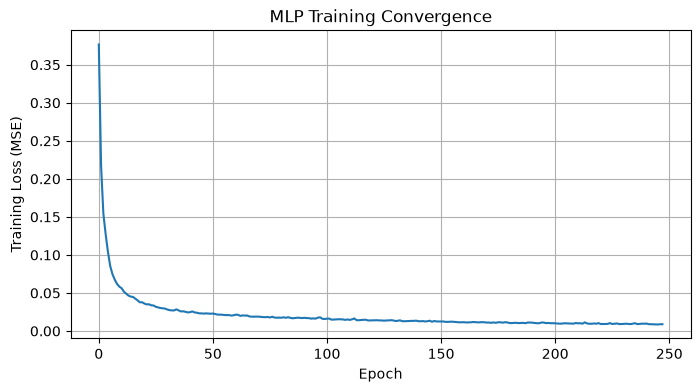

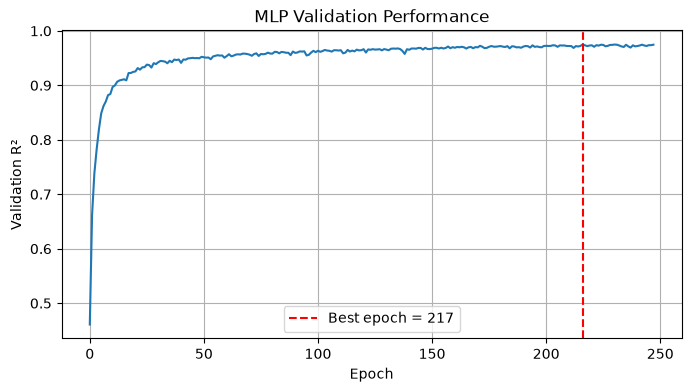

In [15]:
# Plot training loss
plt.figure(figsize=(8, 4))

plt.plot(mlp.loss_curve_)
plt.xlabel("Epoch")
plt.ylabel("Training Loss (MSE)")
plt.title("MLP Training Convergence")
plt.grid(True)
plt.show()

# Plot internal validation R²
plt.figure(figsize=(8, 4))

plt.plot(mlp.validation_scores_)

plt.axvline(
    best_epoch - 1,
    color="red",
    linestyle="--",
    label=f"Best epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Validation R²")
plt.title("MLP Validation Performance")
plt.legend()
plt.grid(True)
plt.show()

## Check training convergence

In [16]:
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# MLP without early stopping
mlp_no_stop = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(128, 64, 32),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            alpha=0.001,
            max_iter=1500,
            early_stopping=False,
            random_state=42
        )
    ),
    transformer=StandardScaler()
)

# Train
mlp_no_stop.fit(X_train, y_train)

# Predict on the SAME validation set
pred_no_stop = mlp_no_stop.predict(X_test)

# Calculate R²
no_stop_scores = {
    target: r2_score(y_test[target], pred_no_stop[:, i])
    for i, target in enumerate(TARGETS)
}

no_stop_scores["mean"] = np.mean(list(no_stop_scores.values()))

# Compare
comparison_stop = pd.DataFrame({
    "Early Stopping": mlp_scores,
    "Without Early Stopping": no_stop_scores
})

display(comparison_stop.round(4))

,Early Stopping,Without Early Stopping
p_1,0.9850,0.9841
a_0,0.9555,0.9494
c_N2,0.9837,0.9819
mean,0.9748,0.9718


## MLP Architecture Optimization

In [17]:
from sklearn.model_selection import KFold
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score

# Define architectures
architectures = {
    "Small (64,32)": (64, 32),
    "Medium (128,64,32)": (128, 64, 32),
    "Large (256,128,64)": (256, 128, 64)
}

# Use the full eligible public dataset
X = preprocess_inputs(A_injected)
y = A_injected[TARGETS]

# Use identical folds for all architectures
kf = KFold(n_splits=5, shuffle=True, random_state=42)

architecture_results = []

for name, layers in architectures.items():

    print(f"\nTraining {name}...")

    for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        model = TransformedTargetRegressor(
            regressor=make_pipeline(
                StandardScaler(),
                MLPRegressor(
                    hidden_layer_sizes=layers,
                    activation="relu",
                    solver="adam",
                    learning_rate_init=0.001,
                    alpha=0.001,
                    max_iter=1500,
                    early_stopping=True,
                    validation_fraction=0.15,
                    n_iter_no_change=30,
                    random_state=42
                )
            ),
            transformer=StandardScaler()
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)

        result = {
            "Architecture": name,
            "Fold": fold
        }

        for i, target in enumerate(TARGETS):
            result[target] = r2_score(y_val[target], pred[:, i])

        result["Mean R²"] = np.mean(
            [result[target] for target in TARGETS]
        )

        architecture_results.append(result)

# Convert results into a DataFrame
architecture_df = pd.DataFrame(architecture_results)

display(architecture_df.round(4))


Training Small (64,32)...

Training Medium (128,64,32)...

Training Large (256,128,64)...


,Architecture,Fold,p_1,a_0,c_N2,Mean R²
0,"Small (64,32)",1,0.9788,0.9489,0.9768,0.9681
1,"Small (64,32)",2,0.9798,0.9471,0.9739,0.9669
2,"Small (64,32)",3,0.9764,0.9485,0.9768,0.9673
3,"Small (64,32)",4,0.9790,0.9456,0.9773,0.9673
4,"Small (64,32)",5,0.9782,0.9386,0.9768,0.9645
5,"Medium (128,64,32)",1,0.9856,0.9670,0.9844,0.9790
6,"Medium (128,64,32)",2,0.9856,0.9620,0.9835,0.9771
7,"Medium (128,64,32)",3,0.9828,0.9615,0.9823,0.9755
8,"Medium (128,64,32)",4,0.9838,0.9610,0.9859,0.9769
9,"Medium (128,64,32)",5,0.9838,0.9547,0.9821,0.9735
